# Spooky Season Escapes; What to Expect When Flying in October

Kylie King (Georgetown University, Data Science and Analytics (DSAN))

## Traveling in October

October is considered a ‘shoulder season’ in most vacation destinations. It is situated between the summer and winter vacation seasons, perfectly in the middle of the back-to-school rush. For most families and students, October is not an ideal time to be traveling. For others, October is the perfect time to secure discounted hotels or visit popular destinations with less crowds. Whether inviting or inconvenient, what does air travel look like during this shoulder season month?

To answer this question, we looked at United States flight records from October 2024. The Department of Transportation provides Airline On-Time Performance datasets through the [TransStats portal](https://www.transtats.bts.gov/). By creating and querying a database for flights in October 2024, we are able to evaluate the busiest time of October to travel, the risks of flight cancellation, and the best airlines to take in October.

## Avoiding the Crowds

[InsureMyTrip analyzed TSA data](https://www.insuremytrip.com/travel-advice/travel-planning/best-worst-time-to-fly-report/) from 2023 to 2026, and found that, on average, the busiest day to fly is Sunday, and the least busy day is Tuesday. How does that yearly average compare to October?

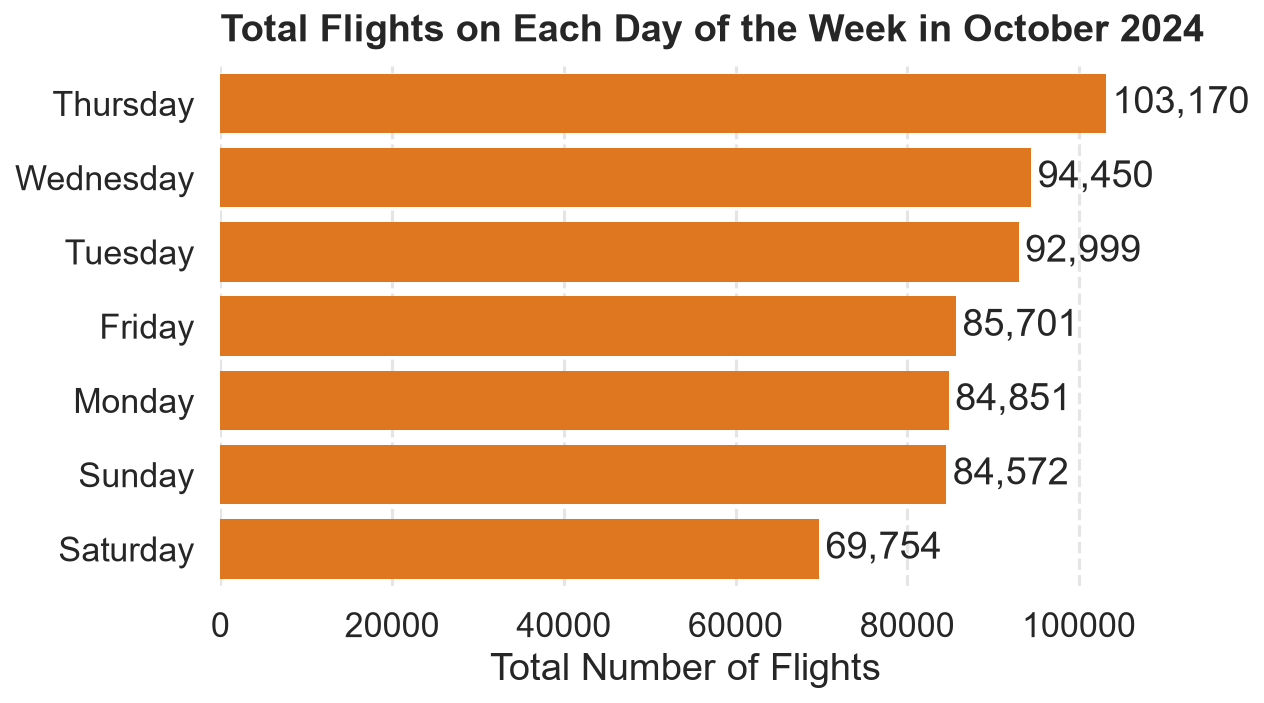

In [1]:
# busiest days
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

weekday_df = pd.read_csv(r"data/kylie_king_kk1543_hw4_problem_03_result.csv")

weekday_df = weekday_df.drop(weekday_df.index[-1]) #removing an 'unknown' date flight

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

sns.barplot(
    data=weekday_df,
    x="Flight_Count",
    y="Day",
    color="#ff7300",
    edgecolor="none",
    ax=ax,
)

ax.set_title("Total Flights on Each Day of the Week in October 2024", loc="left", fontweight="bold", pad=12)
ax.set_xlabel("Total Number of Flights")
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5)
ax.yaxis.grid(False)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
sns.despine(left=True, bottom=True)

With 103,170 flights over the course of October 2024, Thursday is actually the busiest day to fly in October! The slowest day to fly in October is Saturday, which had 69,574 flights in October 2024. Sunday, which is typically seen as the busiest day to fly, only had 84,572 flights in October 2024, making it the second slowest day of the month. Tuesday, which is typically seen as the slowest day to fly, had 92,999 flights in October 2024, making it the third busiest day of the month. This is important to keep in mind when traveling in October, as it directly contradicts the ‘common knowledge’ of flight booking.

It is important to keep in mind, however, that the time of month can also change how busy the airports are. One must consider holidays, long weekends, or other popular travel times. In October 2024, for example, the last week of the month saw significantly fewer flights across all days. In addition, October 31st, the last day of the month, had the second fewest flights of the entire month! This decline in flights is likely because the 31st is Halloween, a fairly popular holiday.

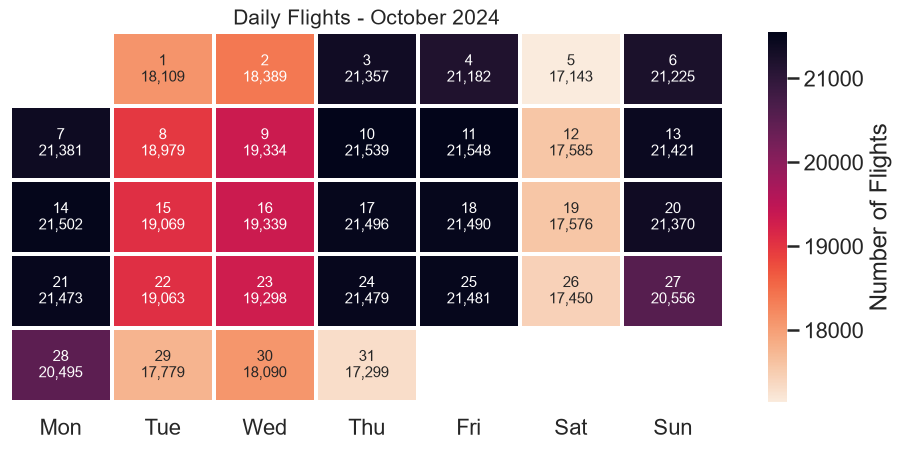

In [2]:
#making a really cool calendar visual
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import calendar

month_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_7_result.csv")
sns.set_theme(style="white", context="talk")

# making sure these are in datetime
month_df['FlightDate'] = pd.to_datetime(month_df['FlightDate'])

#calendar for october 2024
cal = calendar.monthcalendar(2024, 10)

calendar_data = np.full((len(cal), 7), np.nan)
annotations = np.full((len(cal), 7), '', dtype=object)

for week_idx, week in enumerate(cal):
    for day_idx, day in enumerate(week):
        if day != 0:
            flight_count = month_df.loc[
                month_df['FlightDate'].dt.day == day,
                'Flight_Count'
            ]

            count = flight_count.iloc[0] if not flight_count.empty else 0

            calendar_data[week_idx, day_idx] = count

            # date, then number of flights
            annotations[week_idx, day_idx] = f"{day}\n{count:,.0f}"
            

plt.figure(figsize=(12, 5))

sns.heatmap(
    calendar_data,
    annot=annotations,
    fmt='',
    cmap='rocket_r',
    linewidths=3,
    linecolor='white',
    cbar_kws={'label': 'Number of Flights'},
    xticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
    yticklabels=False,
    annot_kws={'fontsize': 11}
)

plt.title('Daily Flights - October 2024', fontsize=16)
plt.xlabel('')
plt.ylabel('')
plt.show()

When traveling in October, keep these findings in mind:

-   Thursday is the busiest day to fly, and Saturday is the least busy
-   The last week of the month is less busy than other weeks
-   Halloween is one of the least busy days of the month to fly

## Cancellation Risks

On any trip, a cancellation could ruin the entire vacation. The webstie [DelayGuard](https://www.delayguard.ai/cancellation-rates) used the exact same Bureau of Transportation Statistics On-Time Performance dataset, looking across the full years 2024-2025. They found that 1.41% of flights in that time period were canceled. How does that average compare to just October?

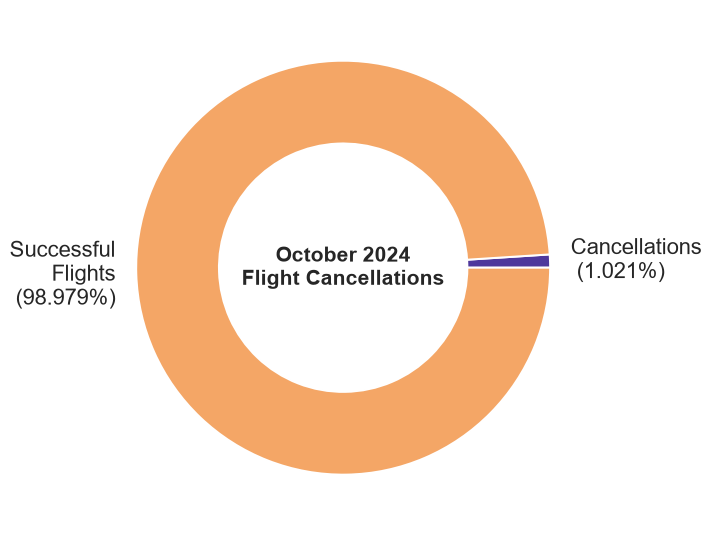

In [3]:
#pie chart of cancellations
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#data
cancel_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_6a_result.csv")
cancellations = cancel_df.at[0, 'Num_Cancelled_Flights']
total_scheduled_flights = weekday_df['Flight_Count'].sum()

plt.figure(figsize=(7, 7))
data = [cancellations, total_scheduled_flights-cancellations] 
total = sum(data)
percentages = [x / total * 100 for x in data]
labels = [
    f'Cancellations\n ({percentages[0]:.3f}%)',
    f'Successful\nFlights\n ({percentages[1]:.3f}%)'
]
colors = ['#4e389c','#f4a666']

plt.pie(data, labels=labels, colors=colors, wedgeprops={'width': 0.4})
plt.text(0, 0, 'October 2024\nFlight Cancellations', ha='center', va='center',
         fontsize=16, fontweight='bold')
plt.show() 

Thankfully, October 2024 had fewer flight cancellations than the average for the rest of the year! With only 1.021% of flights cancelled, a bit less than the 1.41% average, October may be a slightly more reliable time to fly than expected!

It is important to know what exactly causes these cancellations though, so that travelers can plan ahead and anticipate possible changes. At the 184 airports that experienced cancellations in October 2024, “Weather” was the most frequent cancellation reason by far. In the following map, “Weather” was reported as the most frequent cancellation reason for airports in 43 states, while airports in 3 states most frequencly cited “Carrier” (issues within the airline), 2 states most frequencly cited “National Air System” (issues like air traffic or airport operations), and 2 states saw no cancellations in October 2024.

In [4]:
# cancellation reasons by state
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#data
causes_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_6b_result.csv")
causes_df['State'] = causes_df['Airport_Name'].str.extract(r',\s*([A-Z]{2}):')

#parse out state names
state_causes = (causes_df.groupby(['State', 'Most_Freq_Cancellation_Reason'])['Cancellation_Count'].sum().reset_index())

#pull the top cause for each state
top_causes = (state_causes.sort_values('Cancellation_Count', ascending=False).groupby('State').first().reset_index())
#KS and MS didn't have any cancellations, by chance
missing_states = pd.DataFrame({
    'State': ['MS', 'KS'],
    'Most_Freq_Cancellation_Reason': ['No Data', 'No Data'],
    'Cancellation_Count': [0, 0]
})

top_causes = pd.concat([top_causes, missing_states], ignore_index=True)

#choropleth

color_map = {
    'Weather': '#a691ef',
    'Carrier': '#e8c882',
    'National Air System': '#f4a666',
    'No Data': '#9f9f9f'
}

fig = px.choropleth(
    top_causes,
    locations='State',
    locationmode='USA-states',
    color='Most_Freq_Cancellation_Reason',
    hover_name='State',
    hover_data={
        'Most_Freq_Cancellation_Reason': True,
        'Cancellation_Count': False
    },
    scope='usa',
    color_discrete_map=color_map
)

fig.update_layout(
    geo=dict(showlakes=True, lakecolor='white'),
    autosize=True,
    height=None,
    width=None,
    margin=dict(l=0, r=0, t=50, b=50),
    legend=dict(
        orientation='h',
        yanchor='top',
        y=-0.1,
        xanchor='center',
        x=0.5,
        title_text=''
    ),
    title=dict(
        text='<b>Most Frequent Flight Cancellation Reason by State</b>',
        x=0.5,
        xanchor='center',
        y=0.95,
        yanchor='top',
        font=dict(size=14)
    )
)

fig.show(config={'staticPlot': True, 'responsive': True})


When traveling in October, keep these findings in mind:

-   October has slightly fewer flight cancellations than expected when compared to the rest of the year
-   If a flight is cancelled, it is most likely due to weather
-   Keep an eye out for severe storms, tornadoes, hurricanes, or early snows when traveling in October to anticipate cancellations